<a href="https://colab.research.google.com/github/SithmiDesilva/Hallucination-Aware-AI-Framework-for-Trustworthy-Supply-Chain-Decision-Intelligence.-/blob/DataCo_Supply_Chain_Preprocessing/DataCo_tokenized_access_logs_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## SECTION 1: INITIAL SETUP AND DATA LOADING

In [6]:
# ============================================================================
# SECTION 1: SETUP, INSTALLATION & DATA LOADING
# ============================================================================

# Install required packages
!pip install pandas numpy matplotlib seaborn wordcloud -q

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from collections import Counter
import re
from wordcloud import WordCloud
import warnings
warnings.filterwarnings('ignore')

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# File path
file_path = '/content/drive/MyDrive/IRP/Data Co/tokenized_access_logs.csv'

# Load data
try:
    df_raw = pd.read_csv(file_path, encoding='utf-8', low_memory=False)
    print(f"\n Data loaded successfully!")
    print(f"  - Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
    print(f"  - Columns: {list(df_raw.columns)}")
except FileNotFoundError:
    print(f"\n File not found at: {file_path}")
    print("Please upload the file:")
    from google.colab import files
    uploaded = files.upload()
    filename = list(uploaded.keys())[0]
    df_raw = pd.read_csv(filename, encoding='utf-8', low_memory=False)
    print(f"\n Data loaded from upload!")
    print(f"  - Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
except Exception as e:
    print(f"\n Error: {e}")
    df_raw = None

# Quick preview
if df_raw is not None:
    print("\n--- First 5 Rows ---")
    display(df_raw.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

 Data loaded successfully!
  - Shape: 469,977 rows × 8 columns
  - Columns: ['Product', 'Category', 'Date', 'Month', 'Hour', 'Department', 'ip', 'url']

--- First 5 Rows ---


,Product,Category,Date,Month,Hour,Department,ip,url
0,adidas Brazuca 2017 Official Match Ball,baseball & softball,9/1/2017 6:00,Sep,6,fitness,37.97.182.65,/department/fitness/category/baseball%20&%20so...
1,The North Face Women's Recon Backpack,hunting & shooting,9/1/2017 6:00,Sep,6,fan shop,206.56.112.1,/department/fan%20shop/category/hunting%20&%20...
2,adidas Kids' RG III Mid Football Cleat,featured shops,9/1/2017 6:00,Sep,6,apparel,215.143.180.0,/department/apparel/category/featured%20shops/...
3,Under Armour Men's Compression EV SL Slide,electronics,9/1/2017 6:00,Sep,6,footwear,206.56.112.1,/department/footwear/category/electronics/prod...
4,Pelican Sunstream 100 Kayak,water sports,9/1/2017 6:01,Sep,6,fan shop,136.108.56.242,/department/fan%20shop/category/water%20sports...


## SECTION 2: INITIAL DATA INSPECTION (BEFORE PREPROCESSING)

In [7]:
# 2.1 Data Types & Memory
print("\n--- Data Types & Memory Usage ---")
df_raw.info()


--- Data Types & Memory Usage ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 469977 entries, 0 to 469976
Data columns (total 8 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   Product     469977 non-null  object
 1   Category    469977 non-null  object
 2   Date        469977 non-null  object
 3   Month       469977 non-null  object
 4   Hour        469977 non-null  int64 
 5   Department  469977 non-null  object
 6   ip          469977 non-null  object
 7   url         469977 non-null  object
dtypes: int64(1), object(7)
memory usage: 28.7+ MB


In [8]:
# 2.2 Numerical Summary
print("\n--- Numerical Columns Summary ---")
numerical_cols = df_raw.select_dtypes(include=['float64', 'int64']).columns
if len(numerical_cols) > 0:
    display(df_raw[numerical_cols].describe())
else:
    print("No numerical columns found")


--- Numerical Columns Summary ---


,Hour
count,469977.000000
mean,14.591827
std,5.574014
min,0.000000
25%,10.000000
50%,15.000000
75%,20.000000
max,23.000000


In [10]:
# 2.3 Missing Values

missing_df = pd.DataFrame({
    'Column': df_raw.columns,
    'Missing_Count': df_raw.isnull().sum(),
    'Missing_Pct': (df_raw.isnull().sum() / len(df_raw)) * 100
}).sort_values('Missing_Pct', ascending=False)
print(missing_df[missing_df['Missing_Count'] > 0])
if len(missing_df[missing_df['Missing_Count'] > 0]) == 0:
    print(" No missing values found")

Empty DataFrame
Columns: [Column, Missing_Count, Missing_Pct]
Index: []
 No missing values found


In [11]:
# 2.4 Sample data
print("\n--- Sample Data (10 rows) ---")
display(df_raw.head(10))


--- Sample Data (10 rows) ---


,Product,Category,Date,Month,Hour,Department,ip,url
0,adidas Brazuca 2017 Official Match Ball,baseball & softball,9/1/2017 6:00,Sep,6,fitness,37.97.182.65,/department/fitness/category/baseball%20&%20so...
1,The North Face Women's Recon Backpack,hunting & shooting,9/1/2017 6:00,Sep,6,fan shop,206.56.112.1,/department/fan%20shop/category/hunting%20&%20...
2,adidas Kids' RG III Mid Football Cleat,featured shops,9/1/2017 6:00,Sep,6,apparel,215.143.180.0,/department/apparel/category/featured%20shops/...
3,Under Armour Men's Compression EV SL Slide,electronics,9/1/2017 6:00,Sep,6,footwear,206.56.112.1,/department/footwear/category/electronics/prod...
4,Pelican Sunstream 100 Kayak,water sports,9/1/2017 6:01,Sep,6,fan shop,136.108.56.242,/department/fan%20shop/category/water%20sports...
5,Team Golf Tennessee Volunteers Putter Grip,accessories,9/1/2017 6:02,Sep,6,outdoors,116.202.25.156,/department/outdoors/category/accessories/prod...
6,The North Face Women's Recon Backpack,hunting & shooting,9/1/2017 6:02,Sep,6,fan shop,131.132.236.70,/department/fan%20shop/category/hunting%20&%20...
7,Diamondback Boys' Insight 24 Performance Hybr,basketball,9/1/2017 6:02,Sep,6,fitness,30.175.101.147,/department/fitness/category/basketball/produc...
8,Nike Men's Dri-FIT Victory Golf Polo,women's apparel,9/1/2017 6:03,Sep,6,golf,206.56.112.1,/department/golf/category/women's%20apparel/pr...
9,adidas Kids' RG III Mid Football Cleat,featured shops,9/1/2017 6:03,Sep,6,apparel,171.218.47.35,/department/apparel/category/featured%20shops/...


In [12]:
# 2.5 Unique values per object column
print("\n--- Cardinality of Object Columns ---")
obj_cols = df_raw.select_dtypes(include=['object']).columns
cardinality = pd.DataFrame({
    'Column': obj_cols,
    'Unique_Values': [df_raw[c].nunique() for c in obj_cols],
    'Sample': [df_raw[c].dropna().iloc[0] if df_raw[c].notna().any() else 'N/A' for c in obj_cols]
})
display(cardinality)


--- Cardinality of Object Columns ---


,Column,Unique_Values,Sample
0,Product,76,adidas Brazuca 2017 Official Match Ball
1,Category,33,baseball & softball
2,Date,160815,9/1/2017 6:00
3,Month,5,Sep
4,Department,6,fitness
5,ip,3340,37.97.182.65
6,url,152,/department/fitness/category/baseball%20&%20so...


## SECTION 3: BEFORE PREPROCESSING VISUALIZATIONS

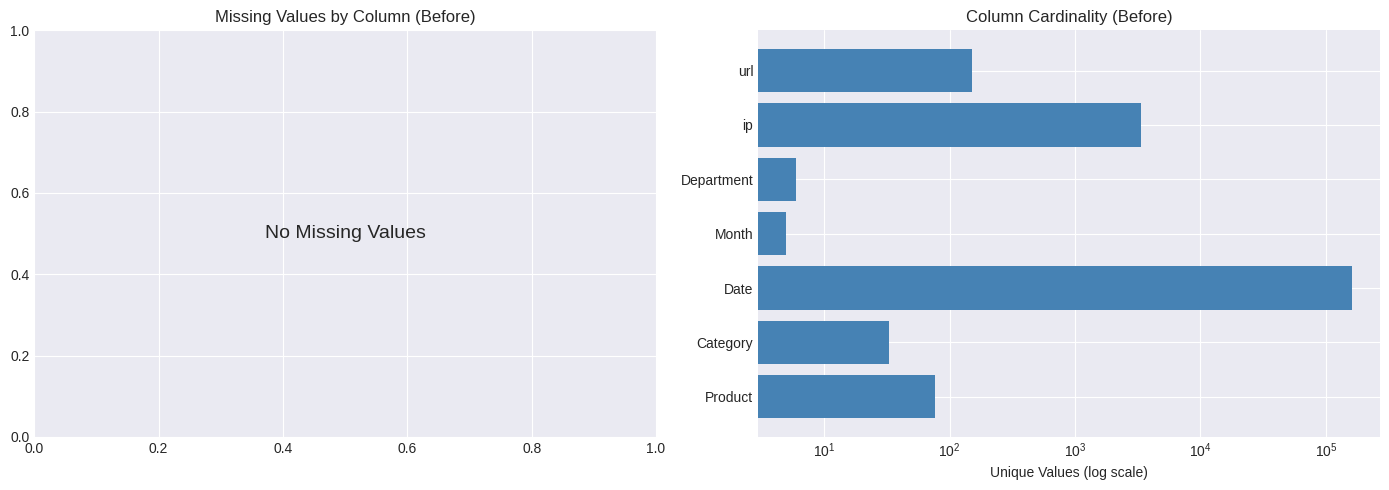

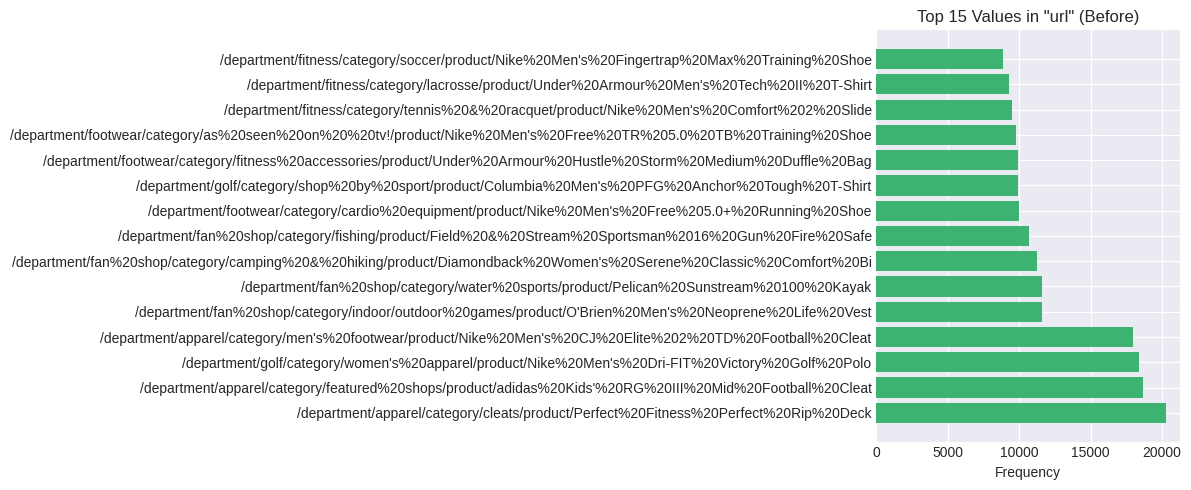

In [16]:

plt.style.use('seaborn-v0_8-darkgrid')

# 3.1 Missing values bar chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

missing_nonzero = missing_df[missing_df['Missing_Count'] > 0]
if len(missing_nonzero) > 0:
    axes[0].barh(missing_nonzero['Column'], missing_nonzero['Missing_Pct'], color='coral')
    axes[0].set_xlabel('Missing %')
    axes[0].set_title('Missing Values by Column (Before)')
else:
    axes[0].text(0.5, 0.5, 'No Missing Values', ha='center', va='center', fontsize=14)
    axes[0].set_title('Missing Values by Column (Before)')

# 3.2 Column cardinality
axes[1].barh(cardinality['Column'], cardinality['Unique_Values'], color='steelblue')
axes[1].set_xlabel('Unique Values (log scale)')
axes[1].set_title('Column Cardinality (Before)')
axes[1].set_xscale('log')

plt.tight_layout()
plt.savefig('section3_before_preprocessing.png', dpi=120, bbox_inches='tight')
plt.show()

# 3.3 Raw URL/column value distribution (if URL-like column exists)
url_col = None
for col in df_raw.columns:
    if any(kw in col.lower() for kw in ['url', 'page', 'path', 'uri', 'link']):
        url_col = col
        break

if url_col:
    fig, ax = plt.subplots(figsize=(12, 5))
    top_vals = df_raw[url_col].value_counts().head(15)
    ax.barh(top_vals.index.astype(str), top_vals.values, color='mediumseagreen')
    ax.set_title(f'Top 15 Values in "{url_col}" (Before)')
    ax.set_xlabel('Frequency')
    plt.tight_layout()
    plt.savefig('section3_url_distribution.png', dpi=120, bbox_inches='tight')
    plt.show()
else:
    print("No URL-like column found for distribution plot")

## SECTION 4: SAMPLING FOR EFFICIENCY

In [17]:
SAMPLE_SIZE = 20000

if df_raw is not None:
    if len(df_raw) > SAMPLE_SIZE:
        df = df_raw.sample(SAMPLE_SIZE, random_state=42).reset_index(drop=True)
        print(f" Sampled {SAMPLE_SIZE:,} rows from {len(df_raw):,} total")
    else:
        df = df_raw.copy()
        print(f" Using full dataset ({len(df):,} rows)")

    print(f"\nWorking dataframe shape: {df.shape}")
    display(df.head(3))
else:
    df = None
    print(" No data to sample")

 Sampled 20,000 rows from 469,977 total

Working dataframe shape: (20000, 8)


,Product,Category,Date,Month,Hour,Department,ip,url
0,Nike Men's Dri-FIT Victory Golf Polo,women's apparel,9/28/2017 2:59,Sep,2,golf,70.101.216.88,/department/golf/category/women's%20apparel/pr...
1,Field & Stream Sportsman 16 Gun Fire Safe,fishing,10/13/2017 23:35,Oct,23,fan shop,61.237.4.104,/department/fan%20shop/category/fishing/produc...
2,Under Armour Men's Tech II T-Shirt,lacrosse,11/10/2017 13:51,Nov,13,fitness,44.244.189.251,/department/fitness/category/lacrosse/product/...


## SECTION 5: URL PARSING

In [19]:
# 5.1 Identify URL column
url_col = None
possible_url_cols = ['url', 'page', 'path', 'link', 'request_uri', 'uri', 'resource']
for col in df.columns:
    for possible in possible_url_cols:
        if possible in col.lower():
            url_col = col
            break
    if url_col:
        break

if url_col is None:
    obj_cols = df.select_dtypes(include=['object']).columns
    url_col = obj_cols[0] if len(obj_cols) > 0 else None
    print(f" Fallback to first object column: {url_col}")
else:
    print(f" URL column identified: {url_col}")

# 5.2 Parse function
def parse_url(url):
    if pd.isna(url):
        return {'department': None, 'category': None, 'subcategory': None, 'product': None}
    s = str(url)
    return {
        'department': (re.search(r'/department/([^/]+)', s) or [None, None])[1],
        'category':   (re.search(r'/category/([^/]+)',   s) or [None, None])[1],
        'subcategory':(re.search(r'/subcategory/([^/]+)',s) or [None, None])[1],
        'product':    (re.search(r'/product/([^/]+)',    s) or [None, None])[1],
    }

if url_col:
    parsed = df[url_col].apply(parse_url)
    df['parsed_department']  = parsed.apply(lambda x: x['department'])
    df['parsed_category']    = parsed.apply(lambda x: x['category'])
    df['parsed_subcategory'] = parsed.apply(lambda x: x['subcategory'])
    df['parsed_product']     = parsed.apply(lambda x: x['product'])

    print("\n--- Parsing Results ---")
    for c in ['parsed_department', 'parsed_category', 'parsed_subcategory', 'parsed_product']:
        n = df[c].notna().sum()
        print(f"  {c}: {n:,} non-null ({n/len(df)*100:.1f}%), {df[c].nunique()} unique")

    # Preview parsed columns
    print("\n--- Sample Parsed Data ---")
    display(df[[url_col, 'parsed_department', 'parsed_category', 'parsed_product']].head(10))

 URL column identified: url

--- Parsing Results ---
  parsed_department: 20,000 non-null (100.0%), 6 unique
  parsed_category: 20,000 non-null (100.0%), 33 unique
  parsed_subcategory: 0 non-null (0.0%), 0 unique
  parsed_product: 20,000 non-null (100.0%), 76 unique

--- Sample Parsed Data ---


,url,parsed_department,parsed_category,parsed_product
0,/department/golf/category/women's%20apparel/pr...,golf,women's%20apparel,Nike%20Men's%20Dri-FIT%20Victory%20Golf%20Polo
1,/department/fan%20shop/category/fishing/produc...,fan%20shop,fishing,Field%20&%20Stream%20Sportsman%2016%20Gun%20Fi...
2,/department/fitness/category/lacrosse/product/...,fitness,lacrosse,Under%20Armour%20Men's%20Tech%20II%20T-Shirt
3,/department/apparel/category/featured%20shops/...,apparel,featured%20shops,adidas%20Kids'%20RG%20III%20Mid%20Football%20C...
4,/department/footwear/category/cardio%20equipme...,footwear,cardio%20equipment,Nike%20Men's%20Free%205.0+%20Running%20Shoe
5,/department/fan%20shop/category/water%20sports...,fan%20shop,water%20sports,Pelican%20Sunstream%20100%20Kayak
6,/department/fitness/category/tennis%20&%20racq...,fitness,tennis%20&%20racquet,Nike%20Men's%20Comfort%202%20Slide
7,/department/apparel/category/men's%20footwear/...,apparel,men's%20footwear,Nike%20Men's%20CJ%20Elite%202%20TD%20Football%...
8,/department/golf/category/shop%20by%20sport/pr...,golf,shop%20by%20sport,Under%20Armour%20Girls'%20Toddler%20Spine%20Su...
9,/department/apparel/category/men's%20footwear/...,apparel,men's%20footwear,Nike%20Men's%20CJ%20Elite%202%20TD%20Football%...
